# 05 · Normalizar por población

California tuvo más muertes que ningún otro estado, pero también es el estado con más habitantes: 61 veces más
que Vermont. Comparar cifras absolutas entre estados es, sobre todo, comparar su tamaño.

En este notebook:

1. Añadimos una **segunda fuente de datos**: la población de cada estado según el US Census Bureau.
2. La **unimos** con los datos de COVID con `merge` por código FIPS y comprobamos que no se pierde nada.
3. Calculamos **casos, muertes y hospitalizados por cada 100.000 habitantes**.
4. **Rehacemos el ranking de estados** con las tasas y lo comparamos con el de cifras absolutas.

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.graficos import AZUL, GRIS, NARANJA, REJILLA, TEXTO, TEXTO_SUAVE, VERDE, aplicar_estilo, formato_miles, miles
from src.poblacion import (COLUMNA_POBLACION, URL_POBLACION, cargar_poblacion, por_100k, preparar_poblacion,
                           unir_poblacion)
from src.variables import REGIONES

aplicar_estilo()

RUTA_VARIABLES = RAIZ / "data" / "processed" / "covid_estados_variables.csv"
RUTA_CENSO = RAIZ / "data" / "raw" / "poblacion_estados_census.csv"
if not RUTA_VARIABLES.exists():
    raise FileNotFoundError("Ejecuta antes los notebooks 01, 02 y 03: generan " + str(RUTA_VARIABLES.relative_to(RAIZ)))

datos = pd.read_csv(RUTA_VARIABLES, parse_dates=["fecha", "semana"])
datos.shape

(20780, 27)

## 1. La segunda fuente: población por estado

- **Fuente:** US Census Bureau, *Annual Estimates of the Resident Population for the United States, Regions,
  States, District of Columbia, and Puerto Rico* (serie 2020-2023, Vintage 2023), fichero `NST-EST2023-ALLDATA.csv`.
  Son datos públicos del Gobierno de Estados Unidos.
- **Qué cifra usamos:** la población estimada a **1 de julio de 2020** (`POPESTIMATE2020`), el punto medio del
  periodo que cubren los datos de COVID (marzo de 2020 a marzo de 2021). Esta serie ya está ajustada al censo de
  2020.
- **Cómo se une:** las dos fuentes tienen el **código FIPS** del estado (un número oficial: 6 es California,
  36 Nueva York...). Es más seguro que el nombre o la abreviatura, que se escriben de formas distintas.

Como con el dataset principal, la primera vez se descarga el CSV a `data/raw/` y después se lee de ahí.

In [2]:
censo = cargar_poblacion(RUTA_CENSO)
print("Origen:", URL_POBLACION)
print("Filas del fichero:", len(censo), "| columnas:", censo.shape[1])
censo[["SUMLEV", "STATE", "NAME", COLUMNA_POBLACION]].head(8)

Origen: https://www2.census.gov/programs-surveys/popest/datasets/2020-2023/state/totals/NST-EST2023-ALLDATA.csv
Filas del fichero: 66 | columnas: 60


,SUMLEV,STATE,NAME,POPESTIMATE2020
0,10,0,United States,331526933
1,20,0,Northeast Region,57430477
2,30,0,New England,15057898
3,30,0,Middle Atlantic,42372579
4,20,0,Midwest Region,68969794
5,30,0,East North Central,47345074
6,30,0,West North Central,21624720
7,20,0,South Region,126465281


El fichero mezcla niveles: la columna `SUMLEV` dice qué es cada fila (10 = el país, 20 = región, 30 = división y
40 = estado). Nos quedamos con los estados, que incluyen DC y Puerto Rico.

In [3]:
poblacion = preparar_poblacion(censo)
estados_censo = poblacion[poblacion["fips"] != 72]   # sin Puerto Rico: 50 estados y DC
total_pais = censo.loc[censo["SUMLEV"] == 10, COLUMNA_POBLACION].iloc[0]

print("Estados en la tabla de población:", len(poblacion), "(50 estados, DC y Puerto Rico)")
print("FIPS repetidos:", poblacion["fips"].duplicated().sum())
print("Suma de los 50 estados y DC:", formato_miles(estados_censo["poblacion"].sum()))
print("Total del país según el propio fichero:", formato_miles(total_pais))
poblacion.sort_values("poblacion", ascending=False).head()

Estados en la tabla de población: 52 (50 estados, DC y Puerto Rico)
FIPS repetidos: 0
Suma de los 50 estados y DC: 331.526.933
Total del país según el propio fichero: 331.526.933


,fips,nombre_estado,poblacion
4,6,California,39503200
43,48,Texas,29234361
9,12,Florida,21591299
32,36,New York,20104710
38,42,Pennsylvania,12995477


La suma de los estados coincide con el total del país que trae el propio fichero: no falta ninguno y no hay
filas repetidas.

## 2. Unir las dos fuentes con `merge`

Unimos por `fips` con:

- `how="left"`: se conservan **todas** las filas de COVID, tengan o no población.
- `validate="many_to_one"`: muchas filas de COVID (una por día) para una sola fila de población por estado.
  Si la tabla de población tuviera un estado repetido, `merge` daría error en vez de duplicar filas sin avisar.

`unir_poblacion()` además comprueba que el número de filas no cambia.

In [4]:
unido = unir_poblacion(datos, poblacion)

print("Filas antes del merge:  ", formato_miles(len(datos)))
print("Filas después del merge:", formato_miles(len(unido)))

sin_poblacion = unido[unido["poblacion"].isna()]
print()
print("Filas sin población:", formato_miles(len(sin_poblacion)))
print("Estados (no territorios) sin población:", sin_poblacion.loc[~sin_poblacion["es_territorio"], "estado"].nunique())
print("Territorios sin población:", sorted(sin_poblacion["estado"].unique()))
print("FIPS de la tabla de población que no aparecen en los datos de COVID:",
      sorted(set(poblacion["fips"]) - set(datos["fips"])))

Filas antes del merge:   20.780
Filas después del merge: 20.780

Filas sin población: 1.428
Estados (no territorios) sin población: 0
Territorios sin población: ['AS', 'GU', 'MP', 'VI']
FIPS de la tabla de población que no aparecen en los datos de COVID: []


- **El merge no pierde ni duplica filas**: hay las mismas antes y después.
- **Los 50 estados y DC tienen población.**
- Solo se quedan sin ella cuatro territorios pequeños (Samoa Americana, Guam, Islas Marianas del Norte e Islas
  Vírgenes), que no están en esta tabla del Census Bureau. Puerto Rico sí está. Como en el resto del análisis,
  trabajamos con los 50 estados y DC, así que no afecta a los resultados.

In [5]:
estados = unido[~unido["es_territorio"]].sort_values(["estado", "fecha"]).copy()
assert estados["poblacion"].notna().all()

# Hospitalizados actuales en media de 7 días: es un dato "en un momento dado", así que miramos su máximo.
estados["hospitalizados_7d"] = estados.groupby("estado")["hospitalizados_actuales"].transform(
    lambda s: s.rolling(7, min_periods=4).mean())
estados.shape

(18995, 30)

## 3. Tasas por cada 100.000 habitantes

Para cada estado, en todo el periodo:

- **Casos y muertes:** el total acumulado dividido entre la población, por 100.000.
- **Hospitalizados:** el número de ingresados cambia cada día y un mismo paciente cuenta muchos días, así que no
  tiene sentido sumarlo. Usamos el **máximo de la media de 7 días** de pacientes ingresados a la vez: mide cuánto
  llegaron a llenarse los hospitales.

Por cada 100.000 habitantes y no en porcentaje porque las muertes son números pequeños: "155 por 100.000" se lee
mejor que "0,155 %".

In [6]:
por_estado = estados.groupby("estado").agg(
    nombre=("nombre_estado", "first"),
    region=("region", "first"),
    poblacion=("poblacion", "first"),
    casos=("casos_nuevos", "sum"),
    muertes=("muertes_nuevas", "sum"),
    hospitalizados_max=("hospitalizados_7d", "max"),
)
for columna in ["casos", "muertes", "hospitalizados_max"]:
    por_estado[columna + "_100k"] = por_100k(por_estado[columna], por_estado["poblacion"])

nacional = {
    "casos": por_100k(por_estado["casos"].sum(), por_estado["poblacion"].sum()),
    "muertes": por_100k(por_estado["muertes"].sum(), por_estado["poblacion"].sum()),
}
print(f"Total del país: {formato_miles(nacional['casos'])} casos y {formato_miles(nacional['muertes'])} muertes "
      "por cada 100.000 habitantes")
print("Estados sin dato de hospitalizados:", por_estado["hospitalizados_max"].isna().sum())

nombres = {"poblacion": "Población", "casos_100k": "Casos / 100.000", "muertes_100k": "Muertes / 100.000",
           "hospitalizados_max_100k": "Máx. hospitalizados / 100.000"}
(por_estado[list(nombres)].rename(columns=nombres).sort_values("Muertes / 100.000", ascending=False)
 .style.format(thousands=".", decimal=",", precision=0))

Total del país: 8.643 casos y 155 muertes por cada 100.000 habitantes
Estados sin dato de hospitalizados: 0


,Población,Casos / 100.000,Muertes / 100.000,Máx. hospitalizados / 100.000
estado,,,,
NJ,9.272.392,8.764,254,86
MA,6.997.713,8.562,235,56
RI,1.096.444,11.757,233,42
MS,2.958.409,10.059,230,50
AZ,7.186.683,11.500,227,69
CT,3.577.586,7.976,215,54
SD,887.852,12.794,214,65
LA,4.652.022,9.327,210,44
AL,5.031.864,9.933,202,60


Las tasas se calculan a partir de **sumas** (total de muertes del estado entre su población), no como media de
tasas diarias: así cada estado pesa lo que le corresponde.

En todo el país hubo unos **8.600 casos y 155 muertes por cada 100.000 habitantes**: uno de cada doce
estadounidenses dio positivo en un año.

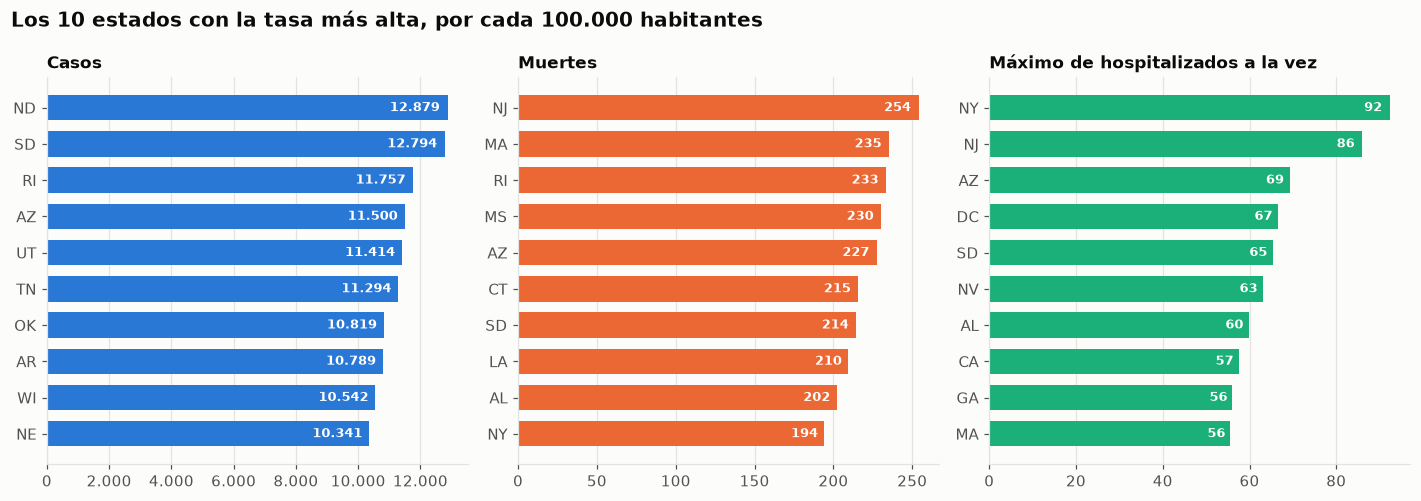

In [7]:
medidas = [
    ("casos_100k", "Casos", AZUL),
    ("muertes_100k", "Muertes", NARANJA),
    ("hospitalizados_max_100k", "Máximo de hospitalizados a la vez", VERDE),
]
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (columna, titulo, color) in zip(ejes, medidas):
    top = por_estado[columna].nlargest(10).sort_values()
    ax.barh(top.index, top, color=color, height=0.7)
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_formatter(miles)
    for posicion, valor in enumerate(top):
        ax.text(valor * 0.98, posicion, formato_miles(valor), va="center", ha="right", color="white",
                fontsize=8.5, fontweight="bold")
fig.suptitle("Los 10 estados con la tasa más alta, por cada 100.000 habitantes", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

Los tres rankings no coinciden:

- **Casos:** los encabezan las Dakotas (Norte y Sur), con más de 12.700 por cada 100.000: casi el 13 % de su
  población dio positivo. Les siguen Rhode Island, Arizona y Utah.
- **Muertes:** Nueva Jersey (254), Massachusetts, Rhode Island, Misisipi y Arizona. Tres de los cinco son del
  Noreste, golpeado en la primavera de 2020, cuando todavía se sabía poco de cómo tratar la enfermedad.
- **Hospitalizados:** el pico más alto por habitante fue el de Nueva York en abril de 2020 (92 ingresados a la vez
  por cada 100.000), por delante de Nueva Jersey y Arizona.

El pico de hospitalizados de la primavera puede quedarse corto en algunos estados: hasta mayo de 2020 no todos
publicaban este dato (ver notebook 04).

## 4. Ranking absoluto frente a ranking por habitante

### 4.1 El ranking absoluto es casi un ranking de población

Si las cifras absolutas sirvieran para comparar, no deberían depender tanto del tamaño de cada estado. Lo medimos
con la **correlación de Spearman**, que compara posiciones en un ranking en lugar de valores.

In [8]:
for columna in ["casos", "muertes"]:
    por_estado[f"puesto_{columna}_abs"] = por_estado[columna].rank(ascending=False, method="min").astype(int)
    por_estado[f"puesto_{columna}_100k"] = por_estado[columna + "_100k"].rank(ascending=False, method="min").astype(int)
por_estado["puesto_poblacion"] = por_estado["poblacion"].rank(ascending=False, method="min").astype(int)

spearman = por_estado[["poblacion", "muertes", "muertes_100k"]].corr(method="spearman")
print("Spearman muertes absolutas - población:   ", round(spearman.loc["muertes", "poblacion"], 2))
print("Spearman muertes por habitante - población:", round(spearman.loc["muertes_100k", "poblacion"], 2))
print("Spearman ranking absoluto - por habitante: ", round(spearman.loc["muertes", "muertes_100k"], 2))

Spearman muertes absolutas - población:    0.94
Spearman muertes por habitante - población: 0.23
Spearman ranking absoluto - por habitante:  0.52


- El ranking de **muertes absolutas** sigue casi punto por punto al de **población** (0,94): dice más del tamaño
  de cada estado que de cómo le fue.
- El ranking **por habitante** tiene una relación débil con la población (0,23): un estado pequeño puede estar
  arriba y uno grande abajo.
- Los dos rankings de muertes se parecen poco entre sí (0,52).

### 4.2 Quién sube y quién baja

In [9]:
cambio = por_estado.assign(diferencia=por_estado["puesto_muertes_abs"] - por_estado["puesto_muertes_100k"])
suben = cambio.nlargest(5, "diferencia").index.tolist()
bajan = cambio.nsmallest(5, "diferencia").index.tolist()

columnas = {"nombre": "Estado", "puesto_muertes_abs": "Puesto (muertes)", "puesto_muertes_100k": "Puesto (por 100.000)",
            "puesto_poblacion": "Puesto (población)", "muertes": "Muertes", "muertes_100k": "Muertes / 100.000"}
tabla = cambio.loc[suben + bajan, list(columnas)].rename(columns=columnas)
tabla.insert(0, "Cambio", ["sube"] * 5 + ["baja"] * 5)
tabla.style.format(thousands=".", decimal=",", precision=0)

,Cambio,Estado,Puesto (muertes),Puesto (por 100.000),Puesto (población),Muertes,Muertes / 100.000
estado,,,,,,,
SD,sube,South Dakota,40,7,46,1.900,214
RI,sube,Rhode Island,35,3,43,2.558,233
ND,sube,North Dakota,42,11,47,1.482,190
DC,sube,District of Columbia,46,24,49,1.032,154
MS,sube,Mississippi,24,4,34,6.808,230
CA,baja,California,1,29,1,54.124,137
NC,baja,North Carolina,15,40,9,11.502,110
FL,baja,Florida,4,27,3,32.266,149
TX,baja,Texas,2,25,2,44.451,152


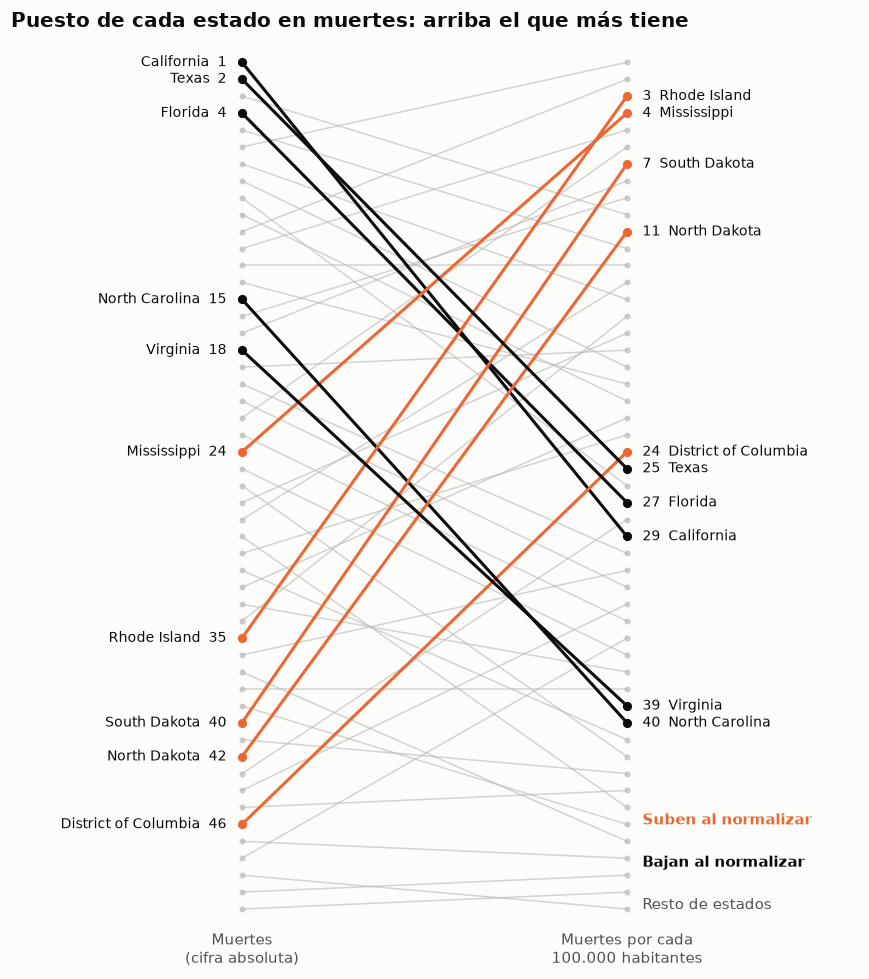

In [10]:
fig, ax = plt.subplots(figsize=(8, 9))
destacados = {**{estado: NARANJA for estado in suben}, **{estado: TEXTO for estado in bajan}}

for estado, fila in por_estado.iterrows():
    color = destacados.get(estado, GRIS)
    resaltado = estado in destacados
    ax.plot([0, 1], [fila["puesto_muertes_abs"], fila["puesto_muertes_100k"]], color=color,
            linewidth=2 if resaltado else 1, alpha=1 if resaltado else 0.6, zorder=3 if resaltado else 2,
            marker="o", markersize=5 if resaltado else 3)
    if resaltado:
        ax.text(-0.04, fila["puesto_muertes_abs"], f"{fila['nombre']}  {fila['puesto_muertes_abs']}",
                ha="right", va="center", fontsize=9, color=TEXTO)
        ax.text(1.04, fila["puesto_muertes_100k"], f"{fila['puesto_muertes_100k']}  {fila['nombre']}",
                ha="left", va="center", fontsize=9, color=TEXTO)

ax.set_ylim(52, 0)
ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1], ["Muertes\n(cifra absoluta)", "Muertes por cada\n100.000 habitantes"], fontsize=10)
ax.set_yticks([])
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.set_title("Puesto de cada estado en muertes: arriba el que más tiene", pad=12)
ax.text(1.04, 46, "Suben al normalizar", color=NARANJA, fontsize=10, fontweight="bold")
ax.text(1.04, 48.5, "Bajan al normalizar", color=TEXTO, fontsize=10, fontweight="bold")
ax.text(1.04, 51, "Resto de estados", color=TEXTO_SUAVE, fontsize=10)
fig.tight_layout()
plt.show()

**Bajan** los estados más poblados: California pasa del puesto 1 al 29, Texas del 2 al 25 y Florida del 4 al 27.
Tuvieron muchas muertes porque tienen mucha gente, pero por habitante quedan en la mitad de la tabla.

**Suben** estados pequeños que en cifras absolutas pasaban desapercibidos: Rhode Island (del 35 al 3), Dakota del
Sur (del 40 al 7) o Dakota del Norte (del 42 al 11). Sus muertes eran pocas en número, pero muchas para su tamaño.

Nueva Jersey ya era sexto en cifras absolutas y pasa a ser **el primero por habitante**: es el estado donde más
golpeó la pandemia en este periodo, con 254 muertes por cada 100.000 habitantes.

## 5. Casos y muertes por habitante: no van siempre juntos

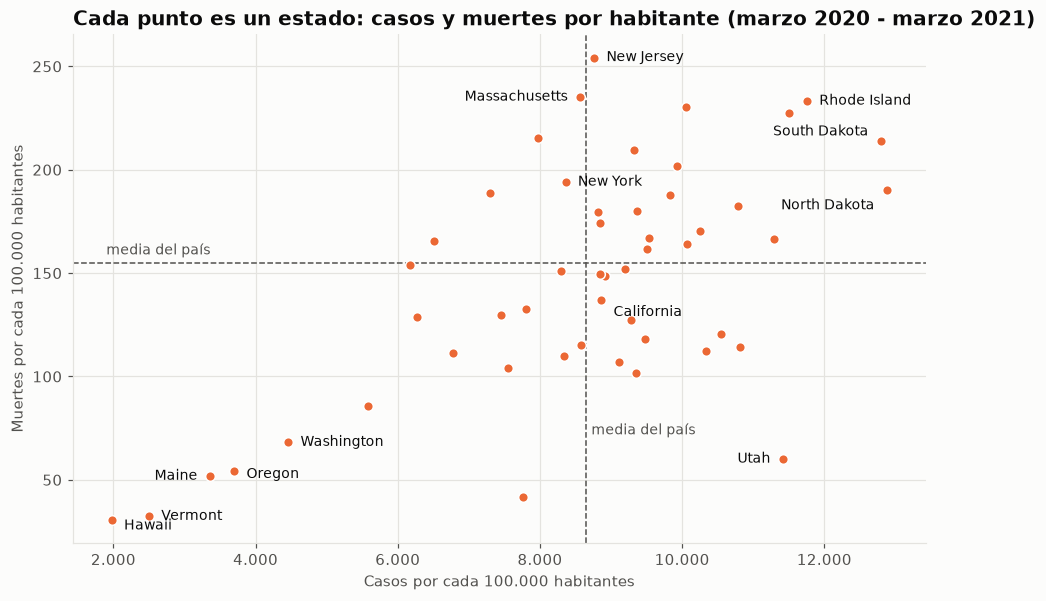

Spearman casos/100.000 - muertes/100.000: 0.46


In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(por_estado["casos_100k"], por_estado["muertes_100k"], s=40, color=NARANJA, edgecolor="white",
           linewidth=1, zorder=3)
ax.axvline(nacional["casos"], color=TEXTO_SUAVE, linewidth=1, linestyle="--", zorder=1)
ax.axhline(nacional["muertes"], color=TEXTO_SUAVE, linewidth=1, linestyle="--", zorder=1)
ax.text(nacional["casos"] + 80, 72, "media del país", color=TEXTO_SUAVE, fontsize=9)
ax.text(1900, nacional["muertes"] + 4, "media del país", color=TEXTO_SUAVE, fontsize=9)

etiquetas = {"NJ": (8, 0), "MA": (-8, 0), "RI": (8, 0), "ND": (-8, -10), "SD": (-8, 6), "UT": (-8, 0),
             "VT": (8, 0), "HI": (8, -4), "CA": (8, -8), "NY": (8, 0), "ME": (-8, 0), "OR": (8, -2),
             "WA": (8, 0)}
for estado, (dx, dy) in etiquetas.items():
    fila = por_estado.loc[estado]
    ax.annotate(fila["nombre"], (fila["casos_100k"], fila["muertes_100k"]), xytext=(dx, dy),
                textcoords="offset points", ha="left" if dx > 0 else "right", va="center", fontsize=9, color=TEXTO)

ax.xaxis.set_major_formatter(miles)
ax.set_xlabel("Casos por cada 100.000 habitantes")
ax.set_ylabel("Muertes por cada 100.000 habitantes")
ax.set_title("Cada punto es un estado: casos y muertes por habitante (marzo 2020 - marzo 2021)")
ax.set_axisbelow(True)
plt.show()

print("Spearman casos/100.000 - muertes/100.000:",
      round(por_estado[["casos_100k", "muertes_100k"]].corr(method="spearman").iloc[0, 1], 2))

Hay relación (más casos por habitante suele ir con más muertes), pero con excepciones claras:

- **Arriba, en el centro, el Noreste** (Nueva Jersey, Massachusetts, Nueva York): casos por habitante en la
  media del país, pero de las muertes más altas. Fueron los primeros golpeados, en la primavera de 2020, cuando se hacían pocas pruebas y
  muchos casos no se detectaron (ver notebook 03).
- **Abajo a la derecha, Utah:** de los que más casos tuvieron por habitante, pero de los que menos muertes. Estos
  datos no explican por qué; la edad de la población, la más joven del país, es una hipótesis que habría que
  comprobar con otra fuente.
- **Abajo a la izquierda,** Hawái, Vermont, Maine y Oregón: pocos casos y pocas muertes.
- **Arriba a la derecha,** las Dakotas: muchos casos y muchas muertes, casi el 90 % de ellas en la ola de
  otoño-invierno.

## 6. Regiones y olas por habitante

En el notebook 03 comparamos el reparto de las muertes de cada ola con el peso de cada región en la población.
Ahora con la población real podemos dar directamente las muertes por cada 100.000 habitantes de cada región en
cada ola.

In [12]:
poblacion_region = por_estado.groupby("region")["poblacion"].sum()
region_ola = estados.groupby(["region", "ola"], observed=True)["muertes_nuevas"].sum().unstack("ola")
region_ola = por_100k(region_ola, poblacion_region.reindex(region_ola.index).to_numpy()[:, None])
region_ola = region_ola.reindex(list(REGIONES))
region_ola.round(1)

ola,1 · primavera 2020,2 · verano 2020,3 · otoño-invierno 2020-21
region,,,
Noreste,99.9,13.1,89.0
Medio Oeste,30.2,14.3,112.1
Sur,15.8,33.7,101.1
Oeste,12.5,22.6,91.6


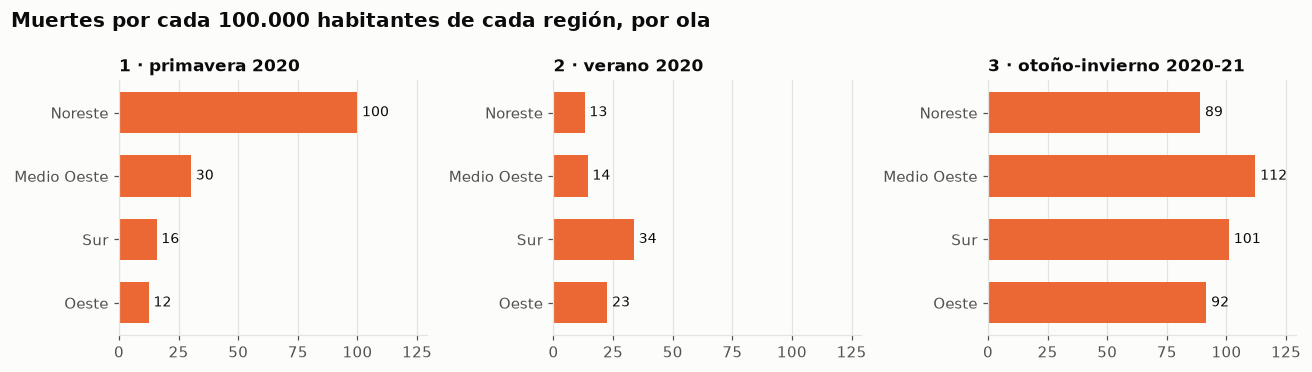

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for ax, ola in zip(ejes, region_ola.columns):
    valores = region_ola[ola].iloc[::-1]
    ax.barh(valores.index, valores, color=NARANJA, height=0.65)
    ax.set_title(ola, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    for posicion, valor in enumerate(valores):
        ax.text(valor + 2, posicion, f"{valor:.0f}", va="center", fontsize=9, color=TEXTO)
ejes[0].set_xlim(0, region_ola.to_numpy().max() * 1.15)
fig.suptitle("Muertes por cada 100.000 habitantes de cada región, por ola", x=0.01, ha="left", fontsize=13,
             fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

- **Primavera de 2020:** el Noreste tuvo unas 100 muertes por cada 100.000 habitantes, más del triple que la
  siguiente región (el Medio Oeste, con 30).
- **Verano de 2020:** fue la ola del Sur (34), aunque mucho más baja que las otras dos en todas las regiones.
- **Otoño-invierno:** todas las regiones quedaron entre 89 y 112, con el Medio Oeste por delante. El Noreste,
  el más golpeado en primavera, fue esta vez el que menos.

Es decir: lo que el Noreste sufrió en unos tres meses de primavera es comparable a lo que las demás regiones
sufrieron en los seis meses de otoño-invierno.

## 7. Guardar los datos con población

Añadimos a los datos diarios la población y tres tasas diarias por cada 100.000 habitantes (medias de 7 días),
para usarlas en los siguientes notebooks y en el dashboard. Los territorios sin población quedan con las tasas
vacías.

In [14]:
salida = unido.sort_values(["estado", "fecha"]).copy()
tasas_diarias = {"casos_nuevos": "casos_100k_7d", "muertes_nuevas": "muertes_100k_7d",
                 "hospitalizados_actuales": "hospitalizados_100k_7d"}
for origen, destino in tasas_diarias.items():
    media_7d = salida.groupby("estado")[origen].transform(lambda s: s.rolling(7, min_periods=4).mean())
    salida[destino] = por_100k(media_7d, salida["poblacion"])

RUTA_SALIDA = RAIZ / "data" / "processed" / "covid_estados_poblacion.csv"
salida.to_csv(RUTA_SALIDA, index=False)
print("Guardado:", RUTA_SALIDA.relative_to(RAIZ), salida.shape)
salida.loc[salida["estado"] == "NJ", ["fecha", "estado", "poblacion", *tasas_diarias.values()]].dropna().tail(3)

Guardado: data\processed\covid_estados_poblacion.csv (20780, 32)


,fecha,estado,poblacion,casos_100k_7d,muertes_100k_7d,hospitalizados_100k_7d
12967,2021-03-05,NJ,9272392.0,36.262796,0.506881,20.413903
12968,2021-03-06,NJ,9272392.0,35.624958,0.491474,20.326085
12969,2021-03-07,NJ,9272392.0,35.825245,0.496096,20.238267


## Conclusiones

- **Segunda fuente:** la población por estado del US Census Bureau a 1 de julio de 2020, unida por código FIPS.
  El merge conserva todas las filas y los 51 estados (50 más DC) tienen población.
- **Las cifras absolutas comparan tamaños:** el ranking de muertes absolutas coincide casi con el de población
  (Spearman 0,94).
- **Por habitante, el mapa cambia:** California, Texas y Florida bajan a mitad de tabla; Rhode Island y las
  Dakotas suben al grupo de cabeza. **Nueva Jersey** es el estado con más muertes por habitante (254 por cada
  100.000), y el Noreste ocupa tres de los cinco primeros puestos.
- **Casos y muertes por habitante no siempre van juntos:** el Noreste tuvo muchas muertes para los casos que se
  detectaron y Utah, muchos casos con pocas muertes.
- **Por regiones:** el Noreste tuvo en la primavera de 2020 tantas muertes por habitante como el resto de
  regiones en todo el otoño-invierno.